## **What Is a Neural Network?**

A neural network is a computational model in machine learning designed around the idea of how biological brains process information. It is built using interconnected processing units called neurons that work together to identify patterns, make predictions, and solve complex tasks such as image recognition, language understanding, and decision-making.

Rather than depending on manually programmed rules, neural networks learn directly from data by adjusting internal parameters during training. Over time, the network strengthens useful connections and weakens unhelpful ones, allowing it to improve its predictions.

Every neural network is constructed from five essential components.


## **Core Components of a Neural Network**

### **1. Neurons**

Neurons are the fundamental building blocks of a neural network. Each neuron receives inputs, multiplies them with associated weights, adds a bias value, and applies an activation function to produce an output.

A neuron becomes significant only when the incoming information is strong enough to activate it meaningfully.

![Neuron](https://media.geeksforgeeks.org/wp-content/uploads/20250703153812268928/bhu.webp)

[Image Source](https://www.geeksforgeeks.org/deep-learning/neural-networks-a-beginners-guide/)

> **Before moving further, what exactly are weights and biases?**


### **2. Weights and Biases**

**Weights** are trainable numerical parameters attached to connections between neurons. They determine the importance of each input feature. A larger weight means the neuron pays more attention to that input, while a smaller weight reduces its influence.

Training a neural network mainly involves finding the optimal set of weight values that minimise prediction errors.

**Biases** are additional trainable values added to the weighted sum before activation. Bias helps the neuron shift its activation threshold, allowing the model to learn more flexible patterns. Without bias, neurons would have very limited representational capability.


### **3. Connections**

Connections are the links that transfer information between neurons. In a dense neural network layer, every neuron connects to all neurons in the following layer, and every connection contains its own weight.

These connections collectively define how information flows through the network architecture.

The coloured arrows shown in the diagram below represent these neuron-to-neuron connections.


### **4. Propagation Functions**

Propagation functions define how neurons process incoming data. In dense layers, the operation usually involves calculating a weighted sum:

[
z = wx + b
]

The computed value is then passed through an activation function to generate the neuron's output. This operation is repeated across multiple layers, enabling the network to gradually extract more meaningful representations from raw input data.


### **5. Learning Rule**

Once the network generates a prediction, it compares the output with the correct answer and measures the error. The model then updates its weights and biases in a direction that reduces this error.

The algorithm responsible for distributing the error across the network is known as **backpropagation**.

$w = w - \eta \frac{\partial \mathcal{L}}{\partial w}$

This equation describes how a weight is updated during training.

Where:

* $(w)$ represents the current weight
* $(\eta)$ is the learning rate
* $(\frac{\partial \mathcal{L}}{\partial w})$ measures how much the weight contributed to the overall error

If a weight increases the error, its value is reduced. If it helps improve predictions, the update increases the weight instead.

The learning rate controls how aggressively the network updates parameters:

* Small values lead to slow but stable learning
* Large values may speed up training but can cause instability

The complete learning cycle usually consists of three major stages:

1. **Feeding Input Data** – data enters the neural network
2. **Generating Predictions** – outputs are produced using current parameters
3. **Updating Parameters** – weights and biases are adjusted to minimise loss

![BackPropagation](https://machinelearningknowledge.ai/wp-content/uploads/2019/10/Backpropagation.gif)

[Source](https://machinelearningknowledge.ai/animated-explanation-of-feed-forward-neural-network-architecture/)


## **Layers in Neural Network Architecture**

A single neuron can only represent simple relationships within data. To solve more advanced problems, neurons are grouped into layers, where each layer extracts increasingly complex features from the previous one.

Initial layers generally learn simple patterns, while deeper layers combine those patterns into higher-level concepts.

Neural networks are commonly organised into three major layer types.

<img src="https://aiforkids.in/images/neural%20networks.png" width="800"/>

[Image Source](https://aiforkids.in/class-9/neural-networks/)


### **Input Layer**

The input layer accepts raw data from the dataset. Each neuron corresponds to a specific input feature and forwards the information to the next layer without performing computations.


### **Hidden Layers**

Hidden layers handle most of the mathematical computations inside the network. By stacking multiple hidden layers, the network can learn hierarchical representations ranging from simple structures to highly abstract features.


### **Output Layer**

The output layer produces the network’s final prediction. Its design depends on the task being solved.

For example:

* Regression problems often use a single output neuron
* Classification tasks may use multiple output neurons


## **Why Neural Networks Are Important**

### **Advanced Pattern Detection**

Neural networks can recognise highly complex structures in images, audio, language, and numerical data that traditional algorithms often fail to capture.

### **Learning From Examples**

Instead of relying on hardcoded instructions, neural networks improve through exposure to training data, becoming more accurate over time.

### **Driving Modern Artificial Intelligence**

Neural networks form the foundation of many AI systems, including:

* Natural Language Processing (NLP)
* Computer Vision
* Speech Recognition
* Recommendation Engines
* Autonomous Systems
* Deep Learning applications developed using TensorFlow


## **Activation Functions - Why Non-Linearity Matters**

If every layer just does matrix multiplication (a linear operation), then *no matter how many layers you stack*, the entire network collapses into a single linear transformation. You could replace 100 layers with 1 and get the same result.

**Activation functions break this collapse.** They introduce non-linearity after each layer, letting the network bend and curve to fit complex patterns.

### **ReLU - Rectified Linear Unit**

$$\text{ReLU}(x) = \max(0, x)$$

<img src="https://debuggercafe.com/wp-content/uploads/2019/04/relu_plot.png" width="800"/>

[Image Source](https://debuggercafe.com/activation-functions-in-neural-networks/)

Any negative value becomes `0`; positive values pass through unchanged.
For example in above graph, for every negative value of x, we are getting 0 (y), and for positive, we are getting the value of x that is y = x.

**Why ReLU is popular:**
- Computationally trivial (one comparison per value)
- Gradients are either `0` or `1` - no squashing, which helps deep networks train faster
- Sparse activations (many zeros) can act as implicit regularisation

**Known limitation:** "Dying ReLU" - if a neuron always receives negative input, its gradient is permanently zero and it stops learning. Variants like `LeakyReLU` or `ELU` address this.

> **In this notebook:** we use `torch.nn.ReLU()` after each hidden layer. The final output layer has *no* activation, because our loss function (MSE) works directly on raw numbers.

## **Loss Functions - Measuring How Wrong the Network Is**

After a forward pass, the network produces predictions. The **loss function** compares those predictions to the true targets and returns a single scalar - a score of "wrongness."

Training is literally the process of minimising this scalar.

### **Mean Squared Error (MSE)**

MSE measures how far off the network's predictions are from the true values, on average. For every prediction, it takes the difference between predicted $\hat{y}$ and actual y, squares it, then averages across all 
N samples.

$$\mathcal{L} = \frac{1}{N} \sum_{i=1}^{N} (\hat{y}_i - y_i)^2$$

- Squares the error, so large mistakes are penalised disproportionately
- Always non-negative; zero means perfect predictions
- Differentiable everywhere - critical for gradient-based optimisation
- Default choice for **regression** problems

PyTorch provides this as `torch.nn.MSELoss()`.

> **Classification uses different losses.** If you were predicting classes instead of numbers, you'd use `CrossEntropyLoss`. MSE works perfectly here because our targets are continuous values.

## **Backward Pass and Optimisation - How the Network Learns**

Training has three phases, repeated for every batch of data:

![forward pass and backward pass](https://kratzert.github.io/images/bn_backpass/chainrule_example.PNG)

[Image Source](https://kratzert.github.io/2016/02/12/understanding-the-gradient-flow-through-the-batch-normalization-layer.html)

### **1. Forward Pass**

Input flows through every layer left to right. Each neuron takes inputs $x$ and $y$, applies $f(x, y)$, and passes the result $z$ forward to the next layer - until a final prediction and loss value come out the other end. PyTorch records every single operation in a **computation graph** as it goes.


### **2. Backward Pass (`loss.backward()`)**

Now the diagram flips red. The loss $\frac{dL}{dz}$ arrives from the right and flows **backwards** through each node. Using the **chain rule**, every node computes how much each of its inputs contributed to the final loss:

$$\frac{dL}{dx} = \frac{dL}{dz} \cdot \frac{dz}{dx} \qquad \frac{dL}{dy} = \frac{dL}{dz} \cdot \frac{dz}{dy}$$

This is the **gradient** - it tells us the direction in which increasing a weight increases the loss. PyTorch stores these for every learnable parameter; that's what `.backward()` does.

### **3. Optimizer Step (`optimizer.step()`)**

The optimizer reads the stored gradients and nudges each weight in the direction that reduces loss:

$$w = w - \eta \cdot \frac{\partial \mathcal{L}}{\partial w}$$

### **Learning Rate $\eta$ 🎯**

The learning rate controls the **size of the step** taken toward the minimum of the loss function after every weight update. Too big and you overshoot. Too small and you crawl.

$$w_{\text{new}} = w_{\text{old}} - \eta \cdot \frac{\partial L}{\partial w}$$

Think of it like descending a hill - you want to move fast enough to make progress, but not so fast that you tumble past the bottom.

![Learning Rate Effects](https://storage.ghost.io/c/38/9a/389ab7af-1195-4ce6-9b1f-d9fb39ea9790/content/images/2018/02/Screen-Shot-2018-02-24-at-11.47.09-AM.png)

[Image Source](https://www.jeremyjordan.me/nn-learning-rate/)

**Too low $\eta$** - takes tiny steps, converges very slowly, can get stuck in a local minimum and never reach the global one.

**Too high $\eta$** - takes giant steps, overshoots the minimum, loss bounces around or even diverges (gets worse over time).

**Just right** - steady, smooth descent toward the minimum in a reasonable number of steps.

**`optimizer.zero_grad()`:**
PyTorch *accumulates* gradients by default. If you don't zero them before each backward pass, gradients from previous batches pile up and corrupt your update. Always call `zero_grad()` first.

```
zero_grad()   →   forward()   →   loss.backward()   →   optimizer.step()
     ↑                                                           |
     └───────────────── repeat every batch ─────────────────────┘
```


# What Is the Network Actually Trying to Do?

## The Setup: Dots on a Graph

Imagine you have **200 dots scattered on a graph.** Each dot is a pair of numbers - an `x` value (how far along the horizontal axis) and a `y` value (how far up the vertical axis). That's it. Just dots.

The network doesn't know where those dots came from. It doesn't know about sine waves, or math, or physics. It only sees the dots.

**Its job: draw a curve that fits through the middle of them.**


## What Is Regression?

**Regression** is the task of finding a curve (or line) that best describes a cloud of points.

A classic example: if you plot house prices against number of bedrooms, more bedrooms tend to mean higher prices. Regression finds that underlying trend, even though the data is noisy and imperfect.

<img src="https://arjun-mota.github.io/assets/img/sample/linear_regression_diagram.png" alt="House Prediction" width="800">

[Image Source](https://github.com/Arjun-Mota/arjun-mota.github.io/blob/main/assets/img/sample/linear_regression_diagram.png)


In our case, the dots were secretly generated from **sin(x)** - but the network doesn't know that. It just sees the cloud and tries to find the pattern.



## **What Is Fitting**?

**Fitting** is the process of adjusting the curve until it matches the data well.

Here's the intuition:

1. The network starts with **random weights** - essentially a random guess at what the curve looks like. It's terrible. The curve might be flat, or a zigzag, or wildly off.

2. The network makes a **prediction**: for a given `x`, it outputs a `y`.

3. It checks **how wrong it was** - the gap between its predicted `y` and the real `y` from the data. This gap is called the *error* or *loss*.

4. It **nudges its weights slightly** in the direction that reduces that error. Just a tiny adjustment.

5. Repeat this many times.

Over time, the weights **gradually settle** into values that produce a curve running through the middle of the dots. The errors get smaller and smaller. The curve gets closer and closer to the true pattern.

That process - adjusting weights over and over until the curve matches the data - is called **fitting the model**.


## **A Well-Fitted Model**

A well-fitted model means the network's output curve runs through the **middle of those noisy dots.** 

At that point, the network has **learned** the underlying pattern of sin(x) - without ever being told the formula. Nobody handed it a textbook. It figured it out purely from looking at dots and getting corrected, over and over, until it got it right.


## **Why Does This Matter?**

Once a network has **fitted a curve to data**, you can use that curve to **predict new values** you've never seen before.

Say your 200 dots only cover `x` values from 0 to 6. After fitting, you can ask the network:  **what's the y value at x = 7?** - and it gives a reasonable answer, because it learned the shape, not just the dots.

That's the core use. Here are concrete examples of the same idea in the real world:


*`Predicting Prices`*
Feed a network thousands of house sales - size, location, age → price. It fits a curve through that cloud of data. Now give it a house it's never seen. It predicts the price.

*`Forecasting the Future`*
Stock prices, energy demand, weather temperature - all time series. Fit a curve to historical data, use it to project forward.


# **Installing Dependencies 📦**

### `pip install` and `!` in Jupyter Notebook

### The `!` Prefix

In Jupyter, `!` runs a **shell command** - as if you typed it directly into your terminal.

```python
!ls
!echo "hello"
```

Normally Jupyter cells run Python. The `!` escapes that - telling Jupyter: *"don't run this as Python, send it to the system shell instead."*


### `!pip install`

`pip` is Python's package manager - it downloads and installs libraries.

```python
!pip install numpy
```

The `!` sends `pip install` to the shell, which fetches the package from the internet and installs it into the current Python environment.

**Why not just `pip install` without `!`?**
Because without `!`, Jupyter tries to run `pip` as Python code - and fails. The `!` is what makes it work inside a notebook cell.


### **PyTorch 🔥**

PyTorch is the library that does all the heavy lifting in this notebook. At its core it gives us two things - **tensors** (think of them as NumPy arrays but smarter) and **autograd** (an engine that automatically tracks every calculation and computes gradients for us during training, so we never have to do the calculus by hand).

On top of that, `torch.nn` gives us ready-made building blocks like layers and loss functions, and `torch.optim` gives us optimizers like SGD and Adam. Instead of writing a neural network from scratch in raw math, we just assemble these pieces together.

It runs on CPU by default, but can use a GPU for much faster training if one is available.

**`!pip install torch torchvision torchaudio`**

> GPU version requires a CUDA-compatible NVIDIA card - get the exact install command for your system at [pytorch.org](https://pytorch.org/get-started/locally/)

### **NumPy 🔢**

Standard Python library for numerical arrays. Used here only to generate synthetic training data before converting it to PyTorch tensors.

### **Matplotlib 📊**

Python's core plotting library. Used here to plot the loss curve after training - a quick visual check that the network actually learned something.

In [1]:
!pip install torch numpy matplotlib

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com

[notice] A new release of pip is available: 23.3.1 -> 26.1.1
[notice] To update, run: python -m pip install --upgrade pip


### **Checking for GPU Support 🖥️**

Before going forward, let's check whether PyTorch can detect a GPU on your machine. This matters because training on a GPU can be orders of magnitude faster than CPU.

We import `torch` and call `torch.cuda.is_available()` - it returns `True` if PyTorch found a CUDA-compatible GPU, `False` if it didn't (meaning everything will run on CPU, which is perfectly fine for this notebook).


> Don't worry if this returns `False` - the notebook runs fine on CPU. GPU becomes important when training much larger networks on real datasets.

In [2]:
import torch
print(f"CUDA available  : {torch.cuda.is_available()}")

CUDA available  : True


## **What Are Tensors? 🧮**

Think of a tensor as just a container for numbers. You already know what a list of numbers is, and what a table of numbers is - tensors are the same idea extended to any number of dimensions.

| Name | Dimensions | Example |
|---|---|---|
| Scalar | 0D | a single number: `3.14` |
| Vector | 1D | a list of numbers: `[1, 2, 3]` |
| Matrix | 2D | a table with rows and columns |
| Tensor | 3D+ | a stack of matrices |

![Scalar Vector Matrix Tensor](https://hadrienj.github.io/assets/images/2.1/scalar-vector-matrix-tensor.png)

[Image Source](https://hadrienj.github.io/posts/Deep-Learning-Book-Series-2.1-Scalars-Vectors-Matrices-and-Tensors/)

If you have used NumPy before, a PyTorch tensor looks and behaves almost exactly like a NumPy array. The difference is two extra abilities:

**GPU support** - a tensor can be moved to a GPU for much faster computation. A NumPy array always runs on CPU only.

**Gradient tracking** - PyTorch watches every operation done on a tensor and remembers it. When training is done, it uses that memory to automatically compute gradients. This is what makes `.backward()` work.

Without these two things, you would have to compute every gradient by hand. Tensors are why we don't have to.

> In this notebook `X` and `y` are tensors holding our data. The weights inside `nn.Linear` are also tensors - PyTorch automatically tracks them so they get updated during training.

## **Generating Synthetic Training Data 📊**

Instead of using a real-world dataset (which would require cleaning, normalisation, and preprocessing), we generate a simple synthetic one so we can stay focused on the network itself.

The relationship we want the network to learn:

$$y = \sin(x) + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 0.1)$$

The clean sine wave is the true underlying pattern. $\varepsilon$ is small random Gaussian noise added on top - simulating the kind of messiness you'd find in real data. The network does not see this formula. It only sees `(X, y)` pairs and must figure out the shape on its own.

![Sine](https://user-images.githubusercontent.com/115313115/206610558-5534c828-b1c3-4bc9-8ec6-30d2592ab9b2.png)

[Image Source](https://github.com/JoydELC/NN_SineWave_arduino)

This is a great example because a single neuron or a linear model cannot fit a sine wave - it's non-linear. It is the perfect test of why we need hidden layers and activation functions.



# **Building the Dataset Step by Step**

## **Imports** 📦

### **What's a Library?**
Python alone can't do maths on arrays.you'd write hundreds of lines from scratch for basic science. Libraries are pre-built, tested, optimised chunks of code you plug in.This way you don't have to reinvent the wheel to run a car.


### **Install vs Import**

Two separate steps - this trips up every beginner.

| Step | Command | Does |
|---|---|---|
| **Install** | `pip install numpy` | Downloads to machine. Once. |
| **Import** | `import numpy` | Loads into *this* script's memory |


### **What's `as np` / `as plt`?**

A nickname. Saves typing, matches every tutorial ever written.

*`numpy.linspace(...)`*        # without alias
*`np.linspace(...)`*           # with alias


### **What Each Does**

**`numpy`** - fast arrays + maths. Used for `linspace`, `sin`, `randn`, `reshape`.

**`matplotlib.pyplot`** - plotting. Used for `plot`, `scatter`, `show`.

**1. Total sample count**
`N_SAMPLES = 200` - total number of data points used for training.

**2. Input (X)**
`np.linspace(-π, π, N_SAMPLES)` - 200 evenly spaced `x` values across one full sine cycle. Cast to `float32` for PyTorch compatibility.

**3. Target (y)**
Each `y` is the sine of `x`, plus a tiny random nudge: `y = sin(x) + ε`. The `ε` is Gaussian noise - small random values drawn from a normal distribution with mean `0` and standard deviation `0.1`. Computed as `0.1 * np.random.randn(N_SAMPLES)`. This makes the data realistic and imperfect, like real-world measurements. Result shape: `(200,)`.

**4. Reshaping**
PyTorch's neural network layers expect data in shape `[batch, features]` - a 2D table, not a flat list. So we reshape both `X` and `y` from `(200,)` → `(200, 1)`. The `y` reshape is specifically **required by `MSELoss`**.

**5. Converting to Tensors**
`torch.FloatTensor` converts NumPy arrays to 32-bit floating-point PyTorch tensors - the default precision for neural network parameters and activations. No gradients are needed for data tensors.

**Data shapes:**
- `X` - shape `(200, 1)` - 200 samples, 1 input feature (the value of `x`)
- `y` - shape `(200, 1)` - one continuous target per sample (the noisy sine value)


### **Visualising the Dataset**

The plot renders two layers over the same `x` axis:

- **True `sin(x)` curve** - the clean, noiseless sine wave drawn as a solid line. This is the ground truth the network is trying to recover.
- **Noisy training samples** - the actual `(x, y)` pairs the network will train on, scattered as small dots with slight transparency (`alpha=0.7`) to show density.

Axis labels, a legend, a dashed reference grid (`alpha=0.3`), and a light background (`#f8f9fa`) are added for readability.

X shape : torch.Size([200, 1])   dtype: torch.float32
y shape : torch.Size([200, 1])   dtype: torch.float32


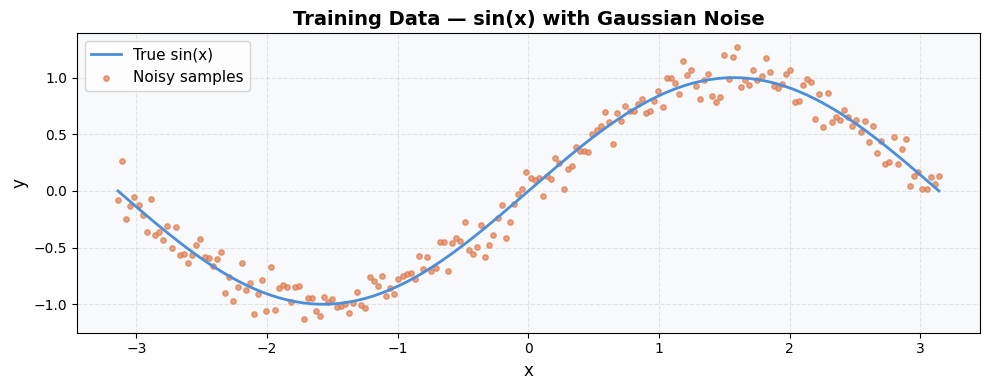

In [7]:
# ── Synthetic Dataset ────────────────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt

N_SAMPLES = 200   # total number of data points

# Input: 200 evenly spaced points between -π and π
X_np = np.linspace(-np.pi, np.pi, N_SAMPLES).astype(np.float32)

# Target: sine of each x value + small Gaussian noise
# y = sin(x) + ε,  ε ~ N(0, 0.1)
noise = 0.1 * np.random.randn(N_SAMPLES).astype(np.float32)
y_np  = np.sin(X_np) + noise              # shape (200,)

# Reshape for PyTorch — nn layers expect shape [batch, features]
X_np = X_np.reshape(-1, 1)               # shape (200, 1)
y_np = y_np.reshape(-1, 1)               # shape (200, 1) — required by MSELoss

# Convert to PyTorch tensors (no gradients needed for data)
X = torch.FloatTensor(X_np)              # shape: [200, 1]
y = torch.FloatTensor(y_np)              # shape: [200, 1]

print(f"X shape : {X.shape}   dtype: {X.dtype}")
print(f"y shape : {y.shape}   dtype: {y.dtype}")

# ── Plot the dataset ─────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(10, 4))

# true clean sine curve
ax.plot(X_np, np.sin(X_np), color='#4c8eda', linewidth=2, label='True sin(x)')

# noisy training samples
ax.scatter(X_np, y_np, color='#e07b4f', s=15, alpha=0.7, label='Noisy samples')

ax.set_xlabel('x',    fontsize=12)
ax.set_ylabel('y',    fontsize=12)
ax.set_title('Training Data — sin(x) with Gaussian Noise', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_facecolor('#f8f9fa')
fig.patch.set_facecolor('#ffffff')

plt.tight_layout()
plt.show()

## **Defining the Neural Network**

We define our model as a Python class that inherits from `nn.Module` - PyTorch's base class for all neural networks. This inheritance gives us automatic parameter tracking, `to(device)` support, and the ability to save/load checkpoints.

**Two methods every `nn.Module` must implement:**

`__init__`
Register all layers here as instance attributes (or inside an `nn.Sequential`). PyTorch scans the class for any attribute that is itself an `nn.Module` and registers those as *submodules*, which means their parameters appear when you call `model.parameters()`.

`forward`
Describe the exact computation: what happens to the input tensor as it flows through the network. PyTorch calls this method when you write `output = model(x)`.

**Architecture in this notebook:**

`Input (1)  →  Linear(1→32)  →  ReLU  →  Linear(32→16)  →  ReLU  →  Linear(16→1)  →  Output`

- Two hidden layers (widths 16 and 8) give the network enough capacity to learn the curved shape of a sine wave
- `nn.ReLU()` after each hidden layer (not the output) introduces non-linearity  essential here since sine is not a straight line
- The output layer outputs a single unbounded number - appropriate for regression

Inside the sequential block:
- `nn.Linear(1, 32)` - first hidden layer, takes 1 input and outputs 32 values
- `nn.ReLU()` - activation after layer 1
- `nn.Linear(32, 16)` - second hidden layer, 32 inputs to 16 outputs
- `nn.ReLU()` - activation after layer 2
- `nn.Linear(16, 1)` - output layer, produces a single predicted value


**`model.parameters()`** returns all learnable tensors (weights and biases) across every layer. We use `p.numel()` to count the total number of individual numbers the network will learn during training.

### Why Input = **1 and Output = 1?**

The network can only accept what you feed it and predict what you ask of it.

**Input size = 1** - each sample is a single number: the value of `x`. Not a vector, not an image, just one float. So the first layer must have exactly 1 input node.

**Output size = 1** - we're predicting one continuous number: the value of `y = sin(x)`. One target per sample, so the last layer must have exactly 1 output node.

These are not design choices. They're locked by the data. Change either and the shapes don't match and the code crashes.


### **Why This Architecture?**

**Why hidden layers at all?**
A single `Linear` layer - no matter how wide - can only draw a straight line. Sine is curved. You need depth to approximate non-linear shapes.

**Why ReLU?**
Without activation functions, stacking linear layers collapses into one linear layer mathematically. `ReLU` breaks linearity after each layer, giving the network the ability to bend and curve its predictions.

**Why no ReLU on the output?**
`ReLU` clamps negative values to zero. The output needs to predict values in `[-1, 1]` freely - clamping would destroy that. Output layer stays raw.

**Why 32 → 16?**
Sine is a smooth, simple curve - it doesn't need thousands of neurons. `32` neurons in the first hidden layer give enough capacity to capture the shape. `16` in the second refines it. Narrowing down (32 → 16 → 1) is a funnel: extract features, compress, predict.

Too few neurons → underfits, can't learn the curve. Too many → overfits, memorises noise.

In [8]:
from torch import nn
class SimpleNet(nn.Module):
    """
    A minimal feed-forward network for regression.

    Architecture
    ------------
    Input(1) → Linear(1→32) → ReLU → Linear(32→16) → ReLU → Linear(16→1)
    """

    def __init__(self):
        super().__init__()                 # must call parent __init__

        # nn.Sequential chains layers; forward() is implicit
        self.network = nn.Sequential(
            nn.Linear(1, 32),             # Layer 1: 1 inputs  → 32 hidden units
            nn.ReLU(),                    # Activation: kills negatives
            nn.Linear(32, 16),             # Layer 2: 32 hidden → 16 hidden units
            nn.ReLU(),                    # Activation
            nn.Linear(16, 1),              # Layer 3: 16 hidden  → 1 output
        )

    def forward(self, x):
        """
        Forward pass: push tensor x through every layer in sequence.
        PyTorch builds the computation graph here, enabling .backward().
        """
        return self.network(x)


# Instantiate the model
model = SimpleNet()

# Print architecture summary
print(model)
print()

# Count total learnable parameters
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total trainable parameters: {total_params:,}")

SimpleNet(
  (network): Sequential(
    (0): Linear(in_features=1, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)

Total trainable parameters: 609


## **Loss Function and Optimizer**

**Loss - `nn.MSELoss()`**
Returns the mean squared error between predictions and targets. PyTorch's implementation is numerically stable and automatically handles batches of any size.

## **Optimizer - Adam**

Regular gradient descent looks at the entire dataset before taking one step toward the minimum. SGD takes a step after every single sample - faster but noisy. **Adam** goes further - it adapts the learning rate individually for each weight based on how gradients have been behaving, and adds momentum to smooth out the updates.


In practice Adam converges faster and is far less sensitive to the learning rate choice than SGD - which is why it is the default optimizer in most modern neural networks.


**`optimizer = optim.Adam(model.parameters(), lr=0.01)`**


- `model.parameters()` - tells Adam which tensors to update
- `lr=0.01` - starting learning rate; Adam will adjust this per-weight automatically during training

> SGD is simpler to understand which is why it appears in most textbooks, but for non-linear problems like fitting a sine wave, Adam is the practical choice.

In [9]:
# ── Loss Function ────────────────────────────────────────────────────────
from torch import nn
from torch import optim

loss_fn = nn.MSELoss()          # Mean Squared Error — standard for regression

# ── Optimizer ────────────────────────────────────────────────────────────

optimizer = optim.Adam(
    model.parameters(),         # tell the optimizer which tensors to update
    lr=0.01,                    # learning rate η
)

print(f"Loss function : {loss_fn}")
print(f"Optimizer     : {optimizer}")

Loss function : MSELoss()
Optimizer     : Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    weight_decay: 0
)


## **The Training Loop 🔁**

This is the heart of every PyTorch model. Every **epoch** is one full pass over the entire dataset. Inside each epoch, five steps run in strict order - skip or shuffle any one of them and training breaks.

**Step 1 - `optimizer.zero_grad()`**

PyTorch doesn't clear gradients automatically - it accumulates them. So before anything else, we wipe the gradients left over from the previous step. Forgetting this means old gradients pile up and corrupt every weight update going forward.

**Step 2 - `predictions = model(X)`**

Data flows forward through every layer - this is the forward pass. PyTorch silently records every operation in a computation graph as it goes, so it knows exactly how each weight contributed to the output.

**Step 3 - `loss = loss_fn(predictions, y)`**

We compare what the network predicted to what the actual answers are. The result is a single number - the loss - telling us how wrong the network currently is. Lower is better; zero would be perfect.

**Step 4 - `loss.backward()`**

Now we go backwards through that recorded computation graph. For every single weight in the network, PyTorch computes how much that weight is responsible for the error and stores it in `w.grad`. This is backpropagation.

**Step 5 - `optimizer.step()`**

The optimizer reads every `w.grad` and nudges each weight slightly in the direction that reduces the loss. This is the actual learning - weights change here and nowhere else.

Repeat all five steps for hundreds of epochs and the loss gradually falls - the network gets less wrong with every pass.

In [10]:
# ── Training Loop ────────────────────────────────────────────────────────

EPOCHS = 2000          # number of full passes over the dataset
loss_history = []     # record loss each epoch for plotting

model.train()         # set model to training mode (matters for Dropout/BatchNorm)

for epoch in range(1, EPOCHS + 1):

    # ── Step 1: Zero gradients from previous iteration ───────────────────
    optimizer.zero_grad()

    # ── Step 2: Forward pass — compute predictions ───────────────────────
    predictions = model(X)              # shape: [200, 1]

    # ── Step 3: Compute loss ─────────────────────────────────────────────
    loss = loss_fn(predictions, y)      # scalar tensor

    # ── Step 4: Backward pass — compute all gradients ────────────────────
    loss.backward()

    # ── Step 5: Update weights ───────────────────────────────────────────
    optimizer.step()

    # ── Logging ──────────────────────────────────────────────────────────
    loss_history.append(loss.item())    # .item() extracts Python float from tensor

    if epoch % 50 == 0 or epoch == 1:
        print(f"Epoch {epoch:>3d}/{EPOCHS}  |  Loss: {loss.item():.6f}")

print()
print(f"Initial loss : {loss_history[0]:.4f}")
print(f"Final loss   : {loss_history[-1]:.4f}")
print(f"Reduction    : {(1 - loss_history[-1]/loss_history[0])*100:.1f}%")

Epoch   1/2000  |  Loss: 0.781214
Epoch  50/2000  |  Loss: 0.028296
Epoch 100/2000  |  Loss: 0.012155
Epoch 150/2000  |  Loss: 0.011534
Epoch 200/2000  |  Loss: 0.011425
Epoch 250/2000  |  Loss: 0.011356
Epoch 300/2000  |  Loss: 0.011335
Epoch 350/2000  |  Loss: 0.011352
Epoch 400/2000  |  Loss: 0.011318
Epoch 450/2000  |  Loss: 0.011320
Epoch 500/2000  |  Loss: 0.011313
Epoch 550/2000  |  Loss: 0.011236
Epoch 600/2000  |  Loss: 0.011337
Epoch 650/2000  |  Loss: 0.011241
Epoch 700/2000  |  Loss: 0.011180
Epoch 750/2000  |  Loss: 0.011181
Epoch 800/2000  |  Loss: 0.011390
Epoch 850/2000  |  Loss: 0.011113
Epoch 900/2000  |  Loss: 0.011078
Epoch 950/2000  |  Loss: 0.011037
Epoch 1000/2000  |  Loss: 0.011038
Epoch 1050/2000  |  Loss: 0.010993
Epoch 1100/2000  |  Loss: 0.011009
Epoch 1150/2000  |  Loss: 0.011131
Epoch 1200/2000  |  Loss: 0.011075
Epoch 1250/2000  |  Loss: 0.011020
Epoch 1300/2000  |  Loss: 0.011159
Epoch 1350/2000  |  Loss: 0.010861
Epoch 1400/2000  |  Loss: 0.010811
Epoch

## **Visualising the Training Loss Curve 📉**

After training, we plot how the loss changed over every epoch. This is called the **loss curve** and it is the first thing anyone checks after training a network - it tells you immediately whether the network actually learned anything or not.

The loss curve is just a graph: epochs on the x-axis, loss value on the y-axis. As the network gets better, the line should trend downward.

**What a healthy curve looks like:**

- Starts high - randomly initialised weights make terrible predictions
- Drops quickly in early epochs - the network is making large corrections fast
- Gradually flattens out - corrections get smaller as weights approach the minimum

**Warning signs to look for:**

- Loss not moving at all - learning rate too small, or a bug in `zero_grad` / `backward` / `step`
- Loss going up or exploding to `NaN` - learning rate too large
- Loss decreasing on training but not on validation data - overfitting (not relevant here since we use all data for training)



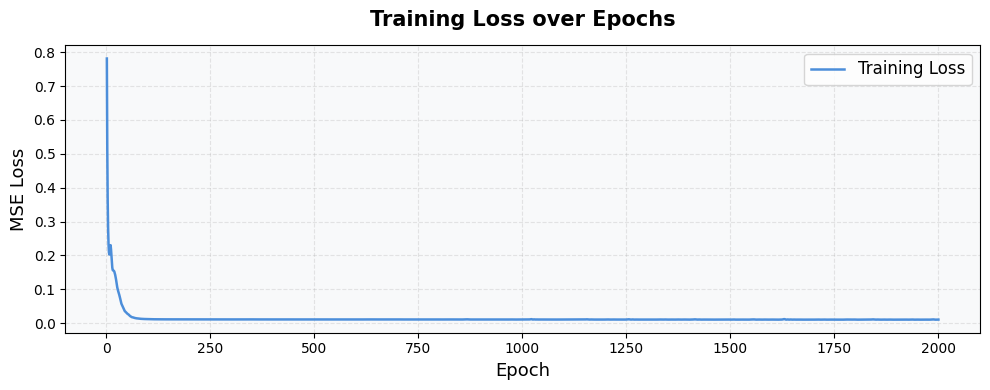

Loss curve saved to loss_curve.png


In [12]:
# ── Loss Curve ───────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(range(1, EPOCHS + 1), loss_history, linewidth=1.8,
        color='#4c8eda', label='Training Loss')

ax.set_xlabel('Epoch',     fontsize=13)
ax.set_ylabel('MSE Loss',  fontsize=13)
ax.set_title('Training Loss over Epochs', fontsize=15, fontweight='bold', pad=14)
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_facecolor('#f8f9fa')
fig.patch.set_facecolor('#ffffff')

plt.tight_layout()
plt.savefig('loss_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print("Loss curve saved to loss_curve.png")

## **Inference and Weight Inspection 🔍**

After training the model is ready to make predictions on new data. Before doing that, two important things:

**`model.eval()`**

During training the model behaves differently than during prediction - some internal mechanics only make sense when learning. Calling `eval()` switches the model into prediction mode, telling it training is over. Even though our simple network isn't affected much, it is good practice to always call this before making predictions.

**`torch.no_grad()`**

During training, PyTorch records every operation on every tensor to build the computation graph - it needs this for `.backward()`. During inference we are not training, so we don't need any of that. Wrapping predictions in `torch.no_grad()` tells PyTorch to stop recording, which saves memory and speeds things up.

**`with torch.no_grad():
    predictions = model(X)`**

**Weight Inspection**

Every `nn.Linear` layer has two learnable tensors you can inspect after training:

- `.weight` - the matrix of weights the layer learned
- `.bias` - the bias values the layer learned

Printing these after training is a sanity check - you can see what values the network settled on after all those gradient updates. If training went well, the numbers should reflect a meaningful pattern rather than random noise.

In [13]:
# ── Inference ────────────────────────────────────────────────────────────

model.eval()                           # evaluation mode

with torch.no_grad():                  # disable gradient computation
    # Test at known points on the sine wave
    test_input  = torch.tensor([[-np.pi],        # expect ≈  0.0
                                 [-np.pi/2],      # expect ≈ -1.0
                                 [0.0],           # expect ≈  0.0
                                 [np.pi/2],       # expect ≈  1.0
                                 [np.pi]])        # expect ≈  0.0
    predictions = model(test_input)

true_values = torch.tensor([[0.0], [-1.0], [0.0], [1.0], [0.0]])

print("Inference results")
print("-" * 45)
print(f"{'Input':<22} {'Predicted':>10} {'True':>8}")
print("-" * 45)
for inp, pred, true in zip(test_input.tolist(), predictions.tolist(), true_values.tolist()):
    print(f"{str(round(inp[0], 4)):<22} {pred[0]:>10.4f} {true[0]:>8.4f}")

print()

# ── Weight Inspection ────────────────────────────────────────────────────
print("Layer 0 weights (shape [16, 1]):")
print(model.network[0].weight.data)
print()
print("Layer 0 bias (shape [16]):")
print(model.network[0].bias.data)

Inference results
---------------------------------------------
Input                   Predicted     True
---------------------------------------------
-3.1416                    0.0182   0.0000
-1.5708                   -0.9965  -1.0000
0.0                        0.0548   0.0000
1.5708                     1.0326   1.0000
3.1416                     0.0881   0.0000

Layer 0 weights (shape [16, 1]):
tensor([[-0.2321],
        [-0.5625],
        [-0.8060],
        [ 0.9928],
        [-0.2770],
        [-0.9239],
        [-0.7881],
        [-0.0383],
        [ 0.6004],
        [-0.0765],
        [ 0.5499],
        [-0.7072],
        [ 0.3994],
        [ 1.0137],
        [ 0.6292],
        [-0.7399],
        [-0.6841],
        [-0.6345],
        [ 0.5252],
        [ 0.7397],
        [ 0.5600],
        [-0.9325],
        [ 0.5032],
        [-0.9964],
        [ 0.9850],
        [-0.2161],
        [-0.6152],
        [ 0.0060],
        [ 0.1085],
        [ 0.1836],
        [ 0.5753],
        [